# Лабораторная №1 по NLP

## Оглавление
1. **Блок 1. Полносвязные нейронные сети (PyTorch)**
   - 1.1 Регрессия: цена автомобиля (`cars_train.csv` / `cars_test.csv`)
   - 1.2 Классификация: опасность астероида (`asteroids_train.csv` / `asteroids_test.csv`)
2. **Блок 2. Контекстные эмбеддинги слов** — предобработка текстов, окна контекста, матрица совпадений
3. **Блок 3. Word2Vec: CBoW и SkipGram**
4. **Блок 4. Визуализация векторных представлений** — PCA, tsv, Projector

## Описание признаков датасета автомобилей (`cars_train.csv` / `cars_test.csv`)

| Признак | Описание | Тип |
|---|---|---|
| `manufacturer_name` | Производитель авто (закодирован числом) | int64, категориальный |
| `transmission` | Тип коробки передач (механика / автомат) | int64, бинарный |
| `odometer_value` | Пробег автомобиля, км | int64, числовой непрерывный |
| `year_produced` | Год выпуска | int64, числовой дискретный |
| `engine_has_gas` | Установлено ли ГБО (газобаллонное оборудование) | int64, бинарный |
| `engine_capacity` | Объём двигателя, л | float64, числовой непрерывный |
| `has_warranty` | Наличие гарантии | int64, бинарный |
| `state` | Состояние автомобиля (закодировано) | int64, категориальный |
| `drivetrain` | Тип привода (передний / задний / полный, закодировано) | int64, категориальный |
| `price_usd` | Цена автомобиля, USD | float64, **целевая переменная (target)** |
| `is_exchangeable` | Возможен ли обмен | int64, бинарный |
| `number_of_photos` | Число фотографий в объявлении | int64, числовой дискретный |
| `up_counter` | Количество поднятий объявления в топ | int64, числовой дискретный |
| `feature_0` … `feature_9` | Дополнительные опции/характеристики авто (10 бинарных признаков) | int64, бинарный |
| `duration_listed` | Сколько дней объявление находится в продаже | int64, числовой дискретный |
| `loc_*` (6 колонок: Брестская, Витебская, Гомельская, Гродненская, Минская, Могилевская обл.) | Регион размещения объявления (Беларусь) | int64, one-hot категориальный |
| `body_*` (12 колонок: cabriolet, coupe, hatchback, liftback, limousine, minibus, minivan, pickup, sedan, suv, universal, van) | Тип кузова автомобиля | int64, one-hot категориальный |
| `fuel_*` (6 колонок: diesel, electric, gas, gasoline, hybrid-diesel, hybrid-petrol) | Тип топлива | int64, one-hot категориальный |

## Импорт библиотек

In [1]:
import torch
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
import torch.nn as nn
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (r2_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import re
import os
from collections import Counter
import nltk
from nltk.corpus import stopwords
import pymorphy3
from razdel import tokenize

torch.__version__

'2.14.1'

# Блок 1. Полносвязные нейронные сети

## 1.1 Регрессия: цена автомобиля

### Загрузка датасета

Разделение на train и test сделано в `01_data_reg.ipynb` **до предобработки** (чтобы параметры предобработки считались только по train и не было утечки данных), поэтому здесь загружаем уже готовые части.

In [2]:
torch.manual_seed(42)  # для воспроизводимости весов и порядка батчей

train_data = pd.read_csv('data/cars_train.csv')
test_data = pd.read_csv('data/cars_test.csv')
train_data

,manufacturer_name,transmission,odometer_value,year_produced,engine_has_gas,engine_capacity,has_warranty,state,drivetrain,price_usd,...,body_sedan,body_suv,body_universal,body_van,fuel_diesel,fuel_electric,fuel_gas,fuel_gasoline,fuel_hybrid-diesel,fuel_hybrid-petrol
0,1,1,2090,2019,0,1.6,0,1,0,18021.43,...,0,0,0,0,0,0,0,1,0,0
1,1,0,303000,2001,0,1.9,0,1,0,6165.23,...,1,0,0,0,1,0,0,0,0,0
2,1,0,300000,1999,1,2.4,0,1,2,5600.00,...,1,0,0,0,0,0,1,0,0,0
3,1,0,110500,2013,0,1.4,0,1,0,9000.00,...,1,0,0,0,0,0,0,1,0,0
4,2,0,196000,2015,0,1.6,0,1,1,17200.00,...,0,0,1,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30787,0,1,310000,2008,0,1.6,0,1,0,7400.00,...,0,0,0,0,1,0,0,0,0,0
30788,1,0,460000,1995,0,1.8,0,1,0,2500.00,...,0,0,1,0,0,0,0,1,0,0
30789,2,0,355222,1996,0,2.0,0,1,0,620.00,...,1,0,0,0,0,0,0,1,0,0
30790,1,1,77921,2014,0,2.0,0,1,2,14900.00,...,0,1,0,0,0,0,0,1,0,0


In [3]:
y_train, X_train = train_data['price_usd'].values, train_data.drop(columns=['price_usd']).values
y_test, X_test = test_data['price_usd'].values, test_data.drop(columns=['price_usd']).values
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

In [4]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((30792, 47), (7699, 47), (30792, 1), (7699, 1))

In [5]:
# масштабирование признаков (X) — fit только на train, чтобы не было утечки данных из test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# логарифмирование таргета (y) — сглаживает длинный хвост дорогих машин
y_train = np.log1p(y_train)
y_test = np.log1p(y_test)


In [6]:
train_ds = TensorDataset(torch.from_numpy(X_train).type(torch.float32), torch.from_numpy(y_train).type(torch.float32))
train_dl = DataLoader(train_ds, batch_size=256, shuffle=True)

test_ds = TensorDataset(torch.from_numpy(X_test).type(torch.float32), torch.from_numpy(y_test).type(torch.float32))
test_dl = DataLoader(test_ds, batch_size=256, shuffle=False)

In [7]:
class RegModel(nn.Module):
    def __init__(self):
        super(RegModel, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(47, 128),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.05),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)

In [8]:
regModel = RegModel()
# определяем функцию потерь
loss = nn.MSELoss()
# настраиваем оптимизатор и передаем туда параметры модели
optimizer = torch.optim.Adam(regModel.parameters(), lr=0.0025)

In [9]:
epochs = 200
epoch_losses = [] # сюда будем сохранять средний loss за каждую эпоху

# цикл обучения (по эпохам)
for epoch in range(epochs):
    batch_losses = []
    # за одну эпоху смотрим все батчи (по batch_size элементов)
    for x_b, y_b in train_dl:
        # делаем прямое распространение (получаем предсказание)
        outputs = regModel(x_b)
        # вычисляем значение функции потерь
        loss_value = loss(outputs, y_b)
        # делаем backward - вычисляются значения .grad у слоев модели
        loss_value.backward()
        # делаем шаг градиентного спуска с заданным у оптимизатора learning_rate
        optimizer.step()
        # зануляем .grad у слоев модели - для нового батча будем акумулировать новый .grad
        optimizer.zero_grad()
        batch_losses.append(loss_value.item())

    epoch_loss = sum(batch_losses) / len(batch_losses)
    epoch_losses.append(epoch_loss)
    
    # в конце эпохи выводим значение функции потерь для последнего рассмотренного батча
    print(f'Эпоха {epoch + 1}, Значение функции потерь: {loss_value.item()}')


Эпоха 1, Значение функции потерь: 1.0876214504241943
Эпоха 2, Значение функции потерь: 0.4098950922489166
Эпоха 3, Значение функции потерь: 1.1832125186920166


Эпоха 4, Значение функции потерь: 0.3432072401046753
Эпоха 5, Значение функции потерь: 0.43351098895072937
Эпоха 6, Значение функции потерь: 0.27353376150131226


Эпоха 7, Значение функции потерь: 0.37579023838043213
Эпоха 8, Значение функции потерь: 0.2705998420715332
Эпоха 9, Значение функции потерь: 0.464182585477829


Эпоха 10, Значение функции потерь: 0.33281585574150085
Эпоха 11, Значение функции потерь: 0.272521436214447
Эпоха 12, Значение функции потерь: 0.3816035985946655


Эпоха 13, Значение функции потерь: 0.21833984553813934
Эпоха 14, Значение функции потерь: 0.25892311334609985
Эпоха 15, Значение функции потерь: 0.26241573691368103


...

Эпоха 187, Значение функции потерь: 0.10548034310340881
Эпоха 188, Значение функции потерь: 0.0822274312376976
Эпоха 189, Значение функции потерь: 0.06069052219390869


Эпоха 190, Значение функции потерь: 0.07416913658380508
Эпоха 191, Значение функции потерь: 0.08189627528190613
Эпоха 192, Значение функции потерь: 0.13189442455768585


Эпоха 193, Значение функции потерь: 0.10460752993822098
Эпоха 194, Значение функции потерь: 0.10887300968170166
Эпоха 195, Значение функции потерь: 0.11589410901069641


Эпоха 196, Значение функции потерь: 0.10597045719623566
Эпоха 197, Значение функции потерь: 0.11522503942251205
Эпоха 198, Значение функции потерь: 0.10284200310707092


Эпоха 199, Значение функции потерь: 0.10893925279378891
Эпоха 200, Значение функции потерь: 0.06581036001443863


In [10]:
regModel.eval()

all_preds = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_dl:
        y_pred = regModel(X_batch)
        all_preds.append(y_pred)
        all_true.append(y_batch)

y_pred = torch.cat(all_preds).numpy()
y_true = torch.cat(all_true).numpy()

# возвращаем из логарифмической шкалы в реальные доллары
y_pred_usd = np.expm1(y_pred)
y_true_usd = np.expm1(y_true)

mae = np.mean(np.abs(y_pred_usd - y_true_usd))
rmse = np.sqrt(np.mean((y_pred_usd - y_true_usd) ** 2))
r2 = r2_score(y_true_usd, y_pred_usd)

metrics_df = pd.DataFrame({
    'Метрика': ['MAE', 'RMSE', 'R2'],
    'Значение': [mae, rmse, r2]
})
metrics_df


,Метрика,Значение
0,MAE,1615.506958
1,RMSE,2860.150391
2,R2,0.797710


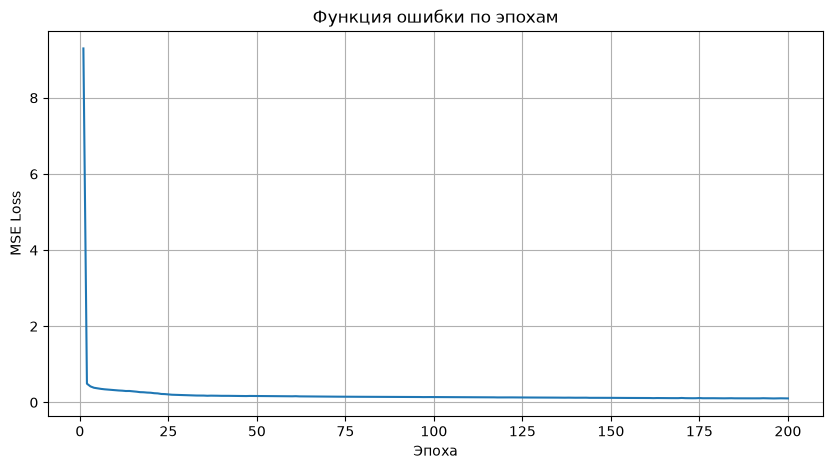

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), epoch_losses)
plt.xlabel('Эпоха')
plt.ylabel('MSE Loss')
plt.title('Функция ошибки по эпохам')
plt.grid(True)
plt.show()

## 1.2 Классификация: опасность астероида

Датасеты `asteroids_train.csv` и `asteroids_test.csv` (результат `02_data_class.ipynb`). Нужно предсказать, является ли объект потенциально опасным.

| Признак | Описание | Тип |
|---|---|---|
| `year` | Год обнаружения (извлечён из названия) | int64, числовой дискретный |
| `est_diameter_max` | Максимальный оценочный диаметр, км | float64, числовой непрерывный |
| `relative_velocity` | Скорость относительно Земли, км/ч (обрезана по 99-му процентилю) | float64, числовой непрерывный |
| `miss_distance` | Расстояние пролёта мимо Земли, км | float64, числовой непрерывный |
| `absolute_magnitude` | Абсолютная звёздная величина (чем меньше, тем ярче/крупнее объект) | float64, числовой непрерывный |
| `hazardous` | Опасен ли объект (0 / 1) | int64, **целевая переменная (target)** |

In [12]:
torch.manual_seed(42)  # для воспроизводимости весов и порядка батчей

train_cls = pd.read_csv('data/asteroids_train.csv')
test_cls = pd.read_csv('data/asteroids_test.csv')

X_cls_train, y_cls_train = train_cls.drop(columns=['hazardous']).values, train_cls['hazardous'].values.copy()
X_cls_test, y_cls_test = test_cls.drop(columns=['hazardous']).values, test_cls['hazardous'].values.copy()

# .copy(): pandas отдаёт массив только для чтения, а torch.from_numpy требует записываемый

# классы несбалансированы: опасных объектов ~10%
train_cls['hazardous'].value_counts(normalize=True)

hazardous
0    0.902969
1    0.097031
Name: proportion, dtype: float64

### Масштабирование

Разделение на train и test сделано в `02_data_class.ipynb` до предобработки и **по объектам**: один астероид пролетает мимо Земли много раз, и все его пролёты попадают в одну часть — иначе сеть проверялась бы на астероидах, которые уже видела при обучении. Доля опасных объектов (~10%) в обеих частях одинаковая.

Масштабирование — как в регрессии: `fit` только на train.

In [13]:
scaler_cls = StandardScaler()
X_cls_train = scaler_cls.fit_transform(X_cls_train)
X_cls_test = scaler_cls.transform(X_cls_test)

X_cls_train.shape, X_cls_test.shape, y_cls_train.mean(), y_cls_test.mean()

((70843, 5),
 (17691, 5),
 np.float64(0.09703146394139153),
 np.float64(0.09733762930303544))

### Dataset и DataLoader

Как и в регрессии, оборачиваем данные в `TensorDataset`, а его — в `DataLoader`, который собирает батчи и перемешивает train на каждой эпохе.

Метки классов храним как `torch.long` — этого требует функция потерь `NLLLoss` (она ждёт номера классов, а не float).

In [14]:
train_cls_ds = TensorDataset(torch.from_numpy(X_cls_train).type(torch.float32), torch.from_numpy(y_cls_train).type(torch.long))
train_cls_dl = DataLoader(train_cls_ds, batch_size=256, shuffle=True)

test_cls_ds = TensorDataset(torch.from_numpy(X_cls_test).type(torch.float32), torch.from_numpy(y_cls_test).type(torch.long))
test_cls_dl = DataLoader(test_cls_ds, batch_size=256, shuffle=False)

len(train_cls_ds), len(test_cls_ds)

(70843, 17691)

### Архитектура с softmax

Особенности решения классификации через softmax:
- на выходе **2 нейрона** — по одному на класс («не опасен», «опасен»), а не 1 нейрон с сигмоидой;
- softmax превращает 2 выхода в вероятности классов, которые в сумме дают 1;
- `nn.CrossEntropyLoss` **уже содержит softmax внутри**, поэтому ставить `nn.Softmax` в сеть и одновременно использовать `CrossEntropyLoss` нельзя — softmax применился бы дважды, и сеть училась бы хуже;
- поэтому последним слоем стоит `nn.LogSoftmax` (логарифм softmax, численно устойчивее обычного softmax), а функция потерь — `nn.NLLLoss`. Связка `LogSoftmax + NLLLoss` математически равна `CrossEntropyLoss`;
- вероятности классов получаем как `exp(выход сети)` — это и есть softmax.

In [15]:
class ClsModel(nn.Module):
    def __init__(self):
        super(ClsModel, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(5, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 2),
            nn.LogSoftmax(dim=1)  # softmax по оси классов
        )

    def forward(self, x):
        return self.net(x)

### Функция потерь с весами классов

Без весов сеть может почти всегда отвечать «не опасен» и всё равно получать accuracy ~90%. Чтобы ошибки на редком классе «стоили» больше, задаём веса классов обратно пропорционально их частоте: `вес = N / (число_классов * N_класса)`.

In [16]:
class_counts = np.bincount(y_cls_train)
class_weights = torch.tensor(len(y_cls_train) / (2 * class_counts), dtype=torch.float32)

clsModel = ClsModel()
loss_cls = nn.NLLLoss(weight=class_weights)
optimizer_cls = torch.optim.Adam(clsModel.parameters(), lr=0.001)

class_weights

tensor([0.5537, 5.1530])

In [17]:
epochs_cls = 50
train_losses_cls = []  # средний loss на train за эпоху
test_losses_cls = []   # средний loss на test за эпоху — чтобы видеть переобучение

for epoch in range(epochs_cls):
    clsModel.train()  # включаем Dropout
    batch_losses = []
    for x_b, y_b in train_cls_dl:
        outputs = clsModel(x_b)
        loss_value = loss_cls(outputs, y_b)
        loss_value.backward()
        optimizer_cls.step()
        optimizer_cls.zero_grad()  # обнуляем градиенты перед следующим батчем
        batch_losses.append(loss_value.item())
    train_losses_cls.append(np.mean(batch_losses))

    clsModel.eval()  # выключаем Dropout
    with torch.no_grad():
        test_batch_losses = [loss_cls(clsModel(x_b), y_b).item() for x_b, y_b in test_cls_dl]
    test_losses_cls.append(np.mean(test_batch_losses))

    if (epoch + 1) % 5 == 0:
        print(f'Эпоха {epoch + 1}, loss train: {train_losses_cls[-1]:.4f}, loss test: {test_losses_cls[-1]:.4f}')

Эпоха 5, loss train: 0.3008, loss test: 0.3050


Эпоха 10, loss train: 0.2942, loss test: 0.3088


Эпоха 15, loss train: 0.2924, loss test: 0.3032


Эпоха 20, loss train: 0.2901, loss test: 0.3017


Эпоха 25, loss train: 0.2891, loss test: 0.3042


Эпоха 30, loss train: 0.2891, loss test: 0.3011


Эпоха 35, loss train: 0.2877, loss test: 0.3035


Эпоха 40, loss train: 0.2875, loss test: 0.3019


Эпоха 45, loss train: 0.2869, loss test: 0.3029


Эпоха 50, loss train: 0.2863, loss test: 0.3051


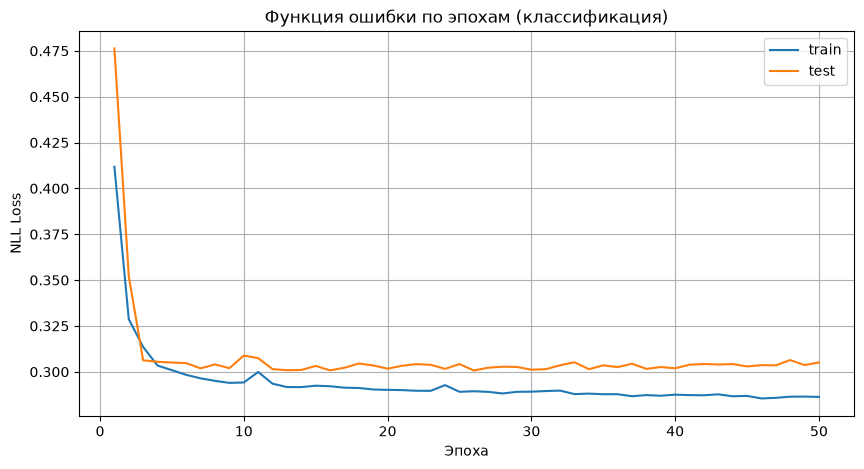

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs_cls + 1), train_losses_cls, label='train')
plt.plot(range(1, epochs_cls + 1), test_losses_cls, label='test')
plt.xlabel('Эпоха')
plt.ylabel('NLL Loss')
plt.title('Функция ошибки по эпохам (классификация)')
plt.legend()
plt.grid(True)
plt.show()

### Оценка качества

Предсказанный класс — тот, у которого вероятность больше (`argmax`). Из-за дисбаланса классов accuracy мало что говорит, основные метрики — **precision, recall и F1 для класса «опасен»** и ROC-AUC (качество ранжирования по вероятности, не зависит от порога).

In [19]:
clsModel.eval()

all_probs = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_cls_dl:
        probs = torch.exp(clsModel(X_batch))  # exp(log_softmax) = softmax -> вероятности классов
        all_probs.append(probs)
        all_true.append(y_batch)

probs = torch.cat(all_probs).numpy()
y_true_cls = torch.cat(all_true).numpy()
y_pred_cls = probs.argmax(axis=1)

metrics_cls_df = pd.DataFrame({
    'Метрика': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Значение': [
        accuracy_score(y_true_cls, y_pred_cls),
        precision_score(y_true_cls, y_pred_cls),
        recall_score(y_true_cls, y_pred_cls),
        f1_score(y_true_cls, y_pred_cls),
        roc_auc_score(y_true_cls, probs[:, 1]),
    ]
})
metrics_cls_df

,Метрика,Значение
0,Accuracy,0.784354
1,Precision,0.309207
2,Recall,0.984901
3,F1,0.470654
4,ROC-AUC,0.918093


              precision    recall  f1-score   support

   не опасен       1.00      0.76      0.86     15969
      опасен       0.31      0.98      0.47      1722

    accuracy                           0.78     17691
   macro avg       0.65      0.87      0.67     17691
weighted avg       0.93      0.78      0.83     17691



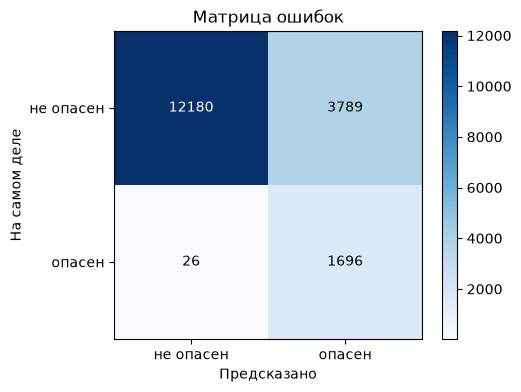

In [20]:
print(classification_report(y_true_cls, y_pred_cls, target_names=['не опасен', 'опасен']))

cm = confusion_matrix(y_true_cls, y_pred_cls)
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
for (r, c), v in np.ndenumerate(cm):
    plt.text(c, r, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
plt.xticks([0, 1], ['не опасен', 'опасен'])
plt.yticks([0, 1], ['не опасен', 'опасен'])
plt.xlabel('Предсказано')
plt.ylabel('На самом деле')
plt.title('Матрица ошибок')
plt.colorbar()
plt.show()

# Блок 2. Контекстные эмбеддинги слов

Дистрибутивная гипотеза: **слова, которые встречаются в похожих контекстах, близки по смыслу**. Самый прямой способ получить из этого векторы слов — **матрица совпадений** (co-occurrence matrix): для каждой пары слов считаем, сколько раз одно слово попало в окно контекста другого. Строка матрицы — это и есть вектор слова.

План блока:
1. загружаем обращения жильцов;
2. предобрабатываем каждый текст по конвейеру **очистка → токенизация → нормализация**;
3. строим словарь;
4. для каждого слова берём окно контекста внутри того же документа;
5. по окнам строим матрицу совпадений и проверяем, что близкие по смыслу слова получили похожие векторы.

## 2.1 Загрузка данных

Датасет `Petitions.csv` — обращения жильцов: `public_petition_text` — текст обращения, `reason_category` — категория (пригодится в блоке 4 для раскраски точек). Короткие одинаковые обращения («Мусор», «Граффити») повторяются сотни раз, поэтому удаляем дубликаты текстов. Используем все уникальные обращения: на подмножестве из 10 000 текстов (~110 тыс. слов) Word2Vec выучивал заметно худшие векторы — для обучения ему нужно больше контекстов.

In [21]:
petitions = pd.read_csv('../data/raw/Petitions.csv')
print('всего обращений:', len(petitions), '| уникальных текстов:', petitions['public_petition_text'].nunique())

petitions = petitions.drop_duplicates(subset='public_petition_text')
petitions = petitions.reset_index(drop=True)
petitions.head(10)

всего обращений: 59889 | уникальных текстов: 43140


,id,public_petition_text,reason_category
0,3168490,снег на дороге,Благоустройство
1,3219678,очистить кабельный киоск от рекламы,Благоустройство
2,2963920,"Просим убрать все деревья и кустарники, которы...",Благоустройство
3,3374910,Неудовлетворительное состояние парадной - надп...,Содержание МКД
4,3336285,Граффити,Благоустройство
5,3130088,Необходимо проверить законность установки выве...,Незаконная информационная и (или) рекламная ко...
6,3333526,"Уборка не производится, на лестнице очень гряз...",Содержание МКД
7,3375258,Мусор,Благоустройство
8,2982491,Отсутствует освещение на лестничной площадке м...,Содержание МКД
9,3375788,"Зачем было делать благоустройство, если никто ...",Благоустройство


## 2.2 Предобработка текста

Конвейер: **очистка → токенизация → нормализация**. Делаем только те шаги, которые нужны для этих данных, поэтому сначала смотрим, какой «мусор» в текстах вообще есть.

In [22]:
texts = petitions['public_petition_text']
noise = {
    'HTML-теги': r'<[^>]+>',
    'email': r'\S+@\S+',
    'URL': r'http\S+|www\.\S+',
    'цифры': r'\d',
    'латиница': r'[a-zA-Z]',
}
pd.Series({name: texts.str.contains(pattern).sum() for name, pattern in noise.items()}, name='текстов')

HTML-теги        2
email            1
URL            126
цифры        19343
латиница      1443
Name: текстов, dtype: int64

### Очистка

«HTML-теги» — на деле 2 цитаты с пропуском `<...>`, email — 1 на весь датасет; отдельно их не чистим, общее правило ниже и так их уберёт. Остальное (URL, цифры — номера домов и даты, латиница — в основном ссылки и анонимизация `XXXXXX`, пунктуация) убирается одним правилом: **оставляем только русские буквы и пробельные символы**. Перед этим приводим текст к нижнему регистру и заменяем `ё` на `е`, чтобы «ещё» и «еще» были одним словом. Лишние пробелы и переносы строк отдельно не чистим — с ними справится токенизатор.

In [23]:
def clean(text):
    text = text.lower().replace('ё', 'е')
    return re.sub(r'[^а-я\s]', ' ', text)

example = texts[texts.str.contains(r'\d')].iloc[0]  # пример с цифрами и пунктуацией
print(example)
print('->', clean(example))

Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная от подъезда №13 до подъезда №15 (фасад дома со стороны ул. Наличной).
-> просим убрать все деревья и кустарники  которые вышли за пределы газона на пешеходную зону  начиная от подъезда     до подъезда      фасад дома со стороны ул  наличной  


### Токенизация

Для русского языка используем `razdel` (проект Natasha) — токенизацию на уровне слов.

In [24]:
def tokenize_text(text):
    return [token.text for token in tokenize(text)]

tokenize_text(clean(example))

['просим',
 'убрать',
 'все',
 'деревья',
 'и',
 'кустарники',
 'которые',
 'вышли',
 'за',
 'пределы',
 'газона',
 'на',
 'пешеходную',
 'зону',
 'начиная',
 'от',
 'подъезда',
 'до',
 'подъезда',
 'фасад',
 'дома',
 'со',
 'стороны',
 'ул',
 'наличной']

### Нормализация

- **Стоп-слова**: список `nltk` + общие слова, которых в нём нет («весь», «это», «который»…) + **доменные стоп-слова** «просить», «просьба» — они есть в огромной доле обращений как вежливая формула и не говорят о сути проблемы. Слова из одной буквы (остатки сокращений «д.», «п.») тоже убираем.
- **Лемматизация** (`pymorphy3`): «батареи», «батарею» → «батарея». Без неё каждая форма слова была бы отдельным словом в словаре, и на каждую приходилось бы меньше контекстов.

Стоп-слово проверяем и в исходной форме, и в лемме: в `nltk` есть «все», но нет его леммы «весь». Лемматизация медленная, поэтому результат для каждого слова запоминаем в `lemma_cache`.

In [25]:
nltk.download('stopwords', quiet=True)
stop_words = {w.replace('ё', 'е') for w in stopwords.words('russian')}
stop_words |= {'весь', 'это', 'который', 'свой', 'наш', 'ваш', 'также', 'очень'}
domain_stop_words = {'просить', 'просьба'}
stop_words |= domain_stop_words

morph = pymorphy3.MorphAnalyzer()
lemma_cache = {}

def lemmatize(word):
    if word not in lemma_cache:
        # pymorphy3 возвращает лемму с «ё» («плёнка»), приводим к одному написанию
        lemma_cache[word] = morph.parse(word)[0].normal_form.replace('ё', 'е')
    return lemma_cache[word]

def normalize(tokens):
    result = []
    for w in tokens:
        lemma = lemmatize(w)
        if w not in stop_words and lemma not in stop_words and len(lemma) > 1:
            result.append(lemma)
    return result

def preprocess(text):
    return normalize(tokenize_text(clean(text)))

# пример: до и после
for t in texts.head(5):
    print(t[:120].replace('\n', ' '))
    print('  ->', preprocess(t))

снег на дороге
  -> ['снег', 'дорога']
очистить кабельный киоск от рекламы
  -> ['очистить', 'кабельный', 'киоск', 'реклама']
Просим убрать все деревья и кустарники, которые вышли за пределы газона на пешеходную зону, начиная от подъезда №13 до п
  -> ['убрать', 'дерево', 'кустарник', 'выйти', 'предел', 'газон', 'пешеходный', 'зона', 'начинать', 'подъезд', 'подъезд', 'фасад', 'дом', 'сторона', 'ул', 'наличный']
Неудовлетворительное состояние парадной - надписи на двери 2 этажа
  -> ['неудовлетворительный', 'состояние', 'парадный', 'надпись', 'дверь', 'этаж']
Граффити
  -> ['граффити']


In [26]:
docs = [preprocess(t) for t in texts]

lengths = pd.Series([len(d) for d in docs])
lengths.describe()

count    43140.000000
mean        11.672786
std         14.303429
min          1.000000
25%          4.000000
50%          7.000000
75%         13.000000
max        224.000000
dtype: float64

## 2.3 Словарь

Считаем частоты слов и оставляем слова, которые встретились хотя бы `min_count = 5` раз: для редкого слова слишком мало контекстов, чтобы выучить осмысленный вектор, а размер словаря напрямую влияет на скорость обучения (выходной слой моделей — по одному нейрону на слово).

Индекс 0 резервируем под служебный токен `<pad>` — им дополняется окно контекста у краёв документа (см. 2.4).

In [27]:
min_count = 5

word_counts = Counter(w for d in docs for w in d)
vocab = [w for w, c in word_counts.most_common() if c >= min_count]

idx2word = ['<pad>'] + vocab
word2idx = {w: i for i, w in enumerate(idx2word)}
vocab_size = len(idx2word)

# убираем из документов редкие слова; документы короче 2 слов не дают ни одного контекста
docs = [[w for w in d if w in word2idx] for d in docs]
keep = [len(d) >= 2 for d in docs]
docs = [d for d, k in zip(docs, keep) if k]
doc_texts = petitions.loc[keep, 'public_petition_text'].tolist()  # исходный текст каждого документа
doc_categories = petitions.loc[keep, 'reason_category'].tolist()  # категория каждого документа (для блока 4)

print('уникальных слов всего:', len(word_counts), '| в словаре:', vocab_size, '| документов:', len(docs))
word_counts.most_common(20)

уникальных слов всего: 16517 | в словаре: 5884 | документов: 42675


[('парадный', 8490),
 ('этаж', 7935),
 ('дом', 7921),
 ('мусор', 6658),
 ('подъезд', 4830),
 ('уборка', 4430),
 ('дверь', 4351),
 ('убрать', 3986),
 ('площадка', 2984),
 ('лифт', 2853),
 ('стена', 2819),
 ('газон', 2803),
 ('состояние', 2775),
 ('надпись', 2592),
 ('фасад', 2559),
 ('требоваться', 2498),
 ('двор', 2491),
 ('лестница', 2402),
 ('снег', 2250),
 ('фото', 2219)]

## 2.4 Окна контекста

Для каждого слова документа (центрального слова) берём `window = 2` слова слева и 2 справа. Окно **не выходит за границы документа**: соседние обращения не связаны по смыслу. Если у края документа соседей меньше, недостающие позиции заполняем `<pad>` — так у всех окон одинаковая длина `2 * window`, и их можно сложить в один тензор.

In [28]:
window = 2

def context_windows(doc, window):
    """Для каждого слова документа возвращает (центральное слово, список слов контекста длины 2*window)."""
    result = []
    for i, center in enumerate(doc):
        context = doc[max(0, i - window):i] + doc[i + 1:i + 1 + window]
        context = context + ['<pad>'] * (2 * window - len(context))
        result.append((center, context))
    return result

# пример на одном документе
example_doc = max(docs[:50], key=len)
print(example_doc, '\n')
for center, context in context_windows(example_doc, window)[:6]:
    print(f'{center:>15}  <-  {context}')

['первый', 'центральный', 'парадный', 'жилой', 'дом', 'адрес', 'гражданский', 'проспект', 'дом', 'корпус', 'литера', 'центр', 'общеквартирный', 'коридор', 'шестой', 'этаж', 'парадный', 'район', 'лифтовый', 'площадка', 'незаконно', 'храниться', 'старый', 'грязный', 'выкинуть', 'деревянный', 'дверь', 'убрать'] 

         первый  <-  ['центральный', 'парадный', '<pad>', '<pad>']
    центральный  <-  ['первый', 'парадный', 'жилой', '<pad>']
       парадный  <-  ['первый', 'центральный', 'жилой', 'дом']
          жилой  <-  ['центральный', 'парадный', 'дом', 'адрес']
            дом  <-  ['парадный', 'жилой', 'адрес', 'гражданский']
          адрес  <-  ['жилой', 'дом', 'гражданский', 'проспект']


## 2.5 Матрица совпадений

Матрица размера `vocab_size × vocab_size`: элемент `[i, j]` — сколько раз слово `j` попало в окно контекста слова `i` во всех документах. Окна берём из 2.4, `<pad>` не считаем. Матрица симметрична: если `j` — сосед `i`, то и `i` — сосед `j`.

Строка `i` — **контекстный вектор слова `i`**: он описывает слово через его соседей. Такие векторы очень длинные (по числу слов в словаре) и разреженные — большинство пар слов рядом никогда не встречаются. Размерность уменьшим с помощью PCA в блоке 4.

In [29]:
cooc_matrix = np.zeros((vocab_size, vocab_size), dtype=np.float32)

for doc in docs:
    for center, context in context_windows(doc, window):
        for c in context:
            if c != '<pad>':
                cooc_matrix[word2idx[center], word2idx[c]] += 1

print('размер:', cooc_matrix.shape)
print('ненулевых элементов: %.2f%%' % ((cooc_matrix > 0).mean() * 100))
print('симметрична:', np.allclose(cooc_matrix, cooc_matrix.T))

# фрагмент матрицы для самых частых слов
top_words = idx2word[1:11]
top_idx = [word2idx[w] for w in top_words]
pd.DataFrame(cooc_matrix[np.ix_(top_idx, top_idx)].astype(int), index=top_words, columns=top_words)

размер: (5884, 5884)
ненулевых элементов: 1.75%


симметрична: True


,парадный,этаж,дом,мусор,подъезд,уборка,дверь,убрать,площадка,лифт
парадный,212,2042,607,184,66,487,712,134,99,475
этаж,2042,442,169,188,906,309,450,88,340,480
дом,607,169,282,297,347,76,79,82,164,43
мусор,184,188,297,164,127,182,19,861,350,19
подъезд,66,906,347,127,188,529,398,60,77,200
уборка,487,309,76,182,529,278,3,32,72,76
дверь,712,450,79,19,398,3,324,30,25,245
убрать,134,88,82,861,60,32,30,42,63,51
площадка,99,340,164,350,77,72,25,63,36,48
лифт,475,480,43,19,200,76,245,51,48,154


### Проверка: ближайшие слова

Близость векторов меряем **косинусным сходством** — косинусом угла между векторами (1 — сонаправлены, 0 — ничего общего). Если матрица совпадений отражает смысл, у слова должны найтись соседи по теме.

In [30]:
def most_similar(word, embeddings, topn=7):
    """Слова с наибольшим косинусным сходством к word по матрице эмбеддингов (строка = слово)."""
    norms = np.linalg.norm(embeddings, axis=1)
    norms[norms == 0] = 1  # у <pad> нулевой вектор
    vec = embeddings[word2idx[word]]
    sims = embeddings @ vec / (norms * np.linalg.norm(vec))
    best = [i for i in np.argsort(-sims) if i != word2idx[word]][:topn]
    return [(idx2word[i], round(float(sims[i]), 3)) for i in best]

check_words = ['батарея', 'вода', 'дерево', 'мусор', 'граффити', 'реклама']
for w in check_words:
    print(f'{w:>10} ->', most_similar(w, cooc_matrix))

   батарея -> [('радиатор', 0.811), ('первый', 0.733), ('второй', 0.729), ('пятый', 0.711), ('третий', 0.708), ('квартира', 0.698), ('мусоропровод', 0.695)]
      вода -> [('кран', 0.66), ('стабильный', 0.576), ('полотенцесушитель', 0.561), ('слабый', 0.549), ('идти', 0.538), ('давление', 0.515), ('подача', 0.511)]
    дерево -> [('ветка', 0.668), ('пни', 0.604), ('куст', 0.562), ('нужно', 0.554), ('покрышка', 0.55), ('кустарник', 0.509), ('листва', 0.508)]
     мусор -> [('листва', 0.653), ('покрышка', 0.628), ('помойка', 0.617), ('снег', 0.611), ('осень', 0.608), ('лист', 0.601), ('нужно', 0.591)]
  граффити -> [('надпись', 0.713), ('цвет', 0.632), ('графити', 0.624), ('разрисовать', 0.583), ('покрасить', 0.568), ('отмыть', 0.562), ('исписать', 0.558)]
   реклама -> [('самоклей', 0.608), ('надпись', 0.602), ('наклейка', 0.586), ('объявление', 0.566), ('граффити', 0.554), ('необходимо', 0.552), ('остаток', 0.498)]


# Блок 3. Word2Vec: CBoW и SkipGram

## 3.1 Обучающие пары

Из тех же окон контекста (2.4) получаются обучающие примеры для двух моделей:
- **CBoW** (Continuous Bag of Words): по контексту предсказываем центральное слово. Один пример = окно из `2 * window` индексов → индекс центрального слова;
- **SkipGram**: наоборот, по центральному слову предсказываем каждое слово контекста. Одно окно даёт до `2 * window` примеров вида «центральное слово → одно слово контекста» (`<pad>` пропускаем).

In [31]:
cbow_X, cbow_y = [], []
skipgram_X, skipgram_y = [], []
pad_idx = word2idx['<pad>']

for doc in docs:
    for center, context in context_windows(doc, window):
        center_idx = word2idx[center]
        context_idx = [word2idx[w] for w in context]

        cbow_X.append(context_idx)
        cbow_y.append(center_idx)

        for c in context_idx:
            if c != pad_idx:
                skipgram_X.append(center_idx)
                skipgram_y.append(c)

cbow_X = torch.tensor(cbow_X, dtype=torch.long)
cbow_y = torch.tensor(cbow_y, dtype=torch.long)
skipgram_X = torch.tensor(skipgram_X, dtype=torch.long)
skipgram_y = torch.tensor(skipgram_y, dtype=torch.long)

cbow_X.shape, cbow_y.shape, skipgram_X.shape, skipgram_y.shape

(torch.Size([485993, 4]),
 torch.Size([485993]),
 torch.Size([1687922]),
 torch.Size([1687922]))

In [32]:
print('CBoW: контекст -> центральное слово')
for i in range(5):
    print('  ', [idx2word[j] for j in cbow_X[i]], '->', idx2word[cbow_y[i]])

print('SkipGram: центральное слово -> слово контекста')
for i in range(5):
    print('  ', idx2word[skipgram_X[i]], '->', idx2word[skipgram_y[i]])

CBoW: контекст -> центральное слово
   ['дорога', '<pad>', '<pad>', '<pad>'] -> снег
   ['снег', '<pad>', '<pad>', '<pad>'] -> дорога
   ['кабельный', 'киоск', '<pad>', '<pad>'] -> очистить
   ['очистить', 'киоск', 'реклама', '<pad>'] -> кабельный
   ['очистить', 'кабельный', 'реклама', '<pad>'] -> киоск
SkipGram: центральное слово -> слово контекста
   снег -> дорога
   дорога -> снег
   очистить -> кабельный
   очистить -> киоск
   кабельный -> очистить


## 3.2 Dataset и DataLoader

Пары уже собраны в тензоры, поэтому, как и в блоке 1, используем `TensorDataset`. Для каждой модели — свой `DataLoader`; `shuffle=True`, чтобы в батче были пары из разных документов.

In [33]:
cbow_ds = TensorDataset(cbow_X, cbow_y)
cbow_dl = DataLoader(cbow_ds, batch_size=512, shuffle=True)

skipgram_ds = TensorDataset(skipgram_X, skipgram_y)
skipgram_dl = DataLoader(skipgram_ds, batch_size=512, shuffle=True)

x_b, y_b = next(iter(cbow_dl))
print('CBoW батч:', x_b.shape, y_b.shape)
x_b, y_b = next(iter(skipgram_dl))
print('SkipGram батч:', x_b.shape, y_b.shape)
len(cbow_ds), len(skipgram_ds)

CBoW батч: torch.Size([512, 4]) torch.Size([512])
SkipGram батч: torch.Size([512]) torch.Size([512])


(485993, 1687922)

## 3.3 Модели

Обе модели состоят из двух слоёв:
- `nn.Embedding(vocab_size, embedding_dim)` — матрица `W` размера «слова × 100». По лекции вектор слова — это one-hot вектор слова, умноженный на `W`; `nn.Embedding` делает то же самое быстрее: по индексу слова просто берёт нужную строку `W`. **Строки этой матрицы после обучения и есть эмбеддинги слов.** `padding_idx=0` — у `<pad>` нулевой вектор, который не обучается;
- `nn.Linear(embedding_dim, vocab_size)` — по вектору выдаёт оценку (логит) для каждого слова словаря: какое слово должно быть ответом.

Отличие моделей только во входе:
- **CBoW**: на входе окно из 4 слов контекста → их векторы **усредняются** (`<pad>` в среднем не участвует) → предсказываем центральное слово;
- **SkipGram**: на входе одно центральное слово → его вектор → предсказываем слово контекста.

Это задача многоклассовой классификации (класс = слово словаря), функция потерь — перекрёстная энтропия. `nn.CrossEntropyLoss` уже содержит softmax внутри, поэтому модели возвращают логиты без softmax.

In [34]:
embedding_dim = 100

class CBOW(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(CBOW, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, context):                          # context: (batch, 2*window)
        emb = self.embedding(context)                    # (batch, 2*window, embedding_dim)
        mask = (context != 0).unsqueeze(-1).float()      # 1 для слов, 0 для <pad>
        mean = (emb * mask).sum(dim=1) / mask.sum(dim=1) # среднее по словам контекста без <pad>
        return self.linear(mean)                         # (batch, vocab_size) — логиты


class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super(SkipGram, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center):                           # center: (batch,)
        return self.linear(self.embedding(center))       # (batch, vocab_size) — логиты

## 3.4 Обучение

Цикл обучения тот же, что в блоке 1, поэтому вынесен в функцию и используется для обеих моделей. Отложенной выборки нет: Word2Vec — это не предсказательная модель, а способ получить векторы, их качество проверяем по ближайшим словам (3.6).

In [35]:
def train_w2v(model, dataloader, epochs, lr=0.001):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    epoch_losses = []

    for epoch in range(epochs):
        batch_losses = []
        for x_b, y_b in dataloader:
            outputs = model(x_b)
            loss_value = loss_fn(outputs, y_b)
            loss_value.backward()
            optimizer.step()
            optimizer.zero_grad()
            batch_losses.append(loss_value.item())
        epoch_losses.append(np.mean(batch_losses))
        print(f'Эпоха {epoch + 1}, loss: {epoch_losses[-1]:.4f}')

    return epoch_losses

In [36]:
torch.manual_seed(42)
cbow_model = CBOW(vocab_size, embedding_dim)
cbow_losses = train_w2v(cbow_model, cbow_dl, epochs=20)

Эпоха 1, loss: 6.8138


Эпоха 2, loss: 5.5851


Эпоха 3, loss: 5.1495


Эпоха 4, loss: 4.8846


Эпоха 5, loss: 4.6997


...

Эпоха 16, loss: 3.9181


Эпоха 17, loss: 3.8819


Эпоха 18, loss: 3.8486


Эпоха 19, loss: 3.8181


Эпоха 20, loss: 3.7886


In [37]:
torch.manual_seed(42)
skipgram_model = SkipGram(vocab_size, embedding_dim)
skipgram_losses = train_w2v(skipgram_model, skipgram_dl, epochs=10)

Эпоха 1, loss: 6.9228


Эпоха 2, loss: 6.2614


Эпоха 3, loss: 6.0981


Эпоха 4, loss: 6.0105


Эпоха 5, loss: 5.9528


Эпоха 6, loss: 5.9101


Эпоха 7, loss: 5.8765


Эпоха 8, loss: 5.8488


Эпоха 9, loss: 5.8254


Эпоха 10, loss: 5.8050


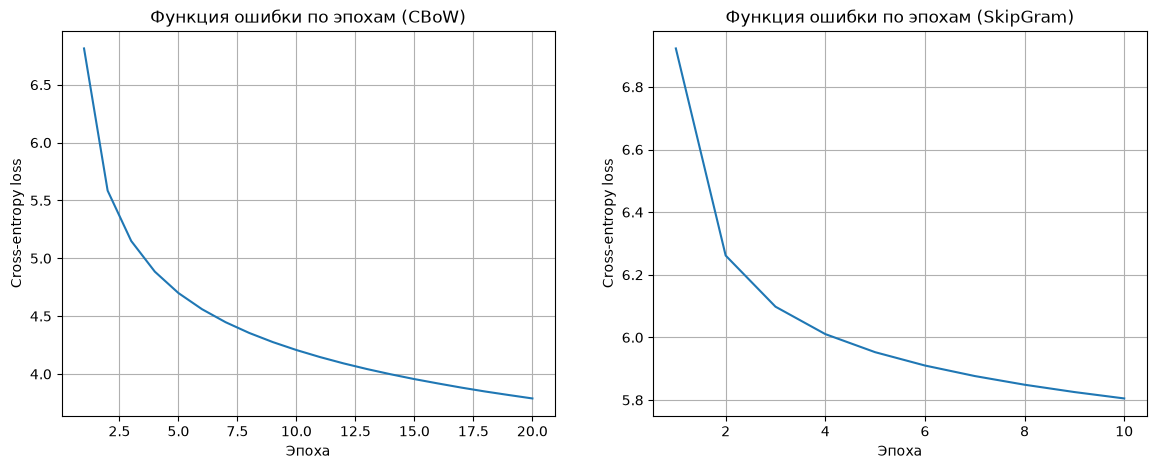

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, losses, title in zip(axes, [cbow_losses, skipgram_losses], ['CBoW', 'SkipGram']):
    ax.plot(range(1, len(losses) + 1), losses)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Cross-entropy loss')
    ax.set_title(f'Функция ошибки по эпохам ({title})')
    ax.grid(True)
plt.show()

## 3.5 Матрицы эмбеддингов

Векторы слов — это веса слоя `Embedding` обученных моделей: строка `i` — вектор слова `idx2word[i]`.

In [39]:
cbow_embeddings = cbow_model.embedding.weight.detach().numpy()
skipgram_embeddings = skipgram_model.embedding.weight.detach().numpy()

cbow_embeddings.shape, skipgram_embeddings.shape

((5884, 100), (5884, 100))

## 3.6 Сравнение трёх способов

Ближайшие по косинусному сходству слова для тех же слов, что в 2.5, — по матрице совпадений, CBoW и SkipGram.

In [40]:
comparison = pd.DataFrame({
    name: [', '.join(w for w, _ in most_similar(word, emb, topn=5)) for word in check_words]
    for name, emb in [('матрица совпадений', cooc_matrix), ('CBoW', cbow_embeddings), ('SkipGram', skipgram_embeddings)]
}, index=check_words)
comparison

,матрица совпадений,CBoW,SkipGram
батарея,"радиатор, первый, второй, пятый, третий","радиатор, труба, кафель, подведение, петля","петля, отопление, радиатор, лаз, прохладный"
вода,"кран, стабильный, полотенцесушитель, слабый, идти","солнечный, отопление, кипяток, полотенцесушите...","горячий, дождевой, отвод, кипяток, стекать"
дерево,"ветка, пни, куст, нужно, покрышка","тополь, палка, ограда, куст, ветка","береза, спилить, перерасти, надломить, куст"
мусор,"листва, покрышка, помойка, снег, осень","отход, эксплуатировать, бункер, макулатура, ок...","пакет, окурок, макулатура, эксплуатировать, ра..."
граффити,"надпись, цвет, графити, разрисовать, покрасить","надпись, рисунок, графити, реклама, клей","надпись, закрасить, реклама, графити, разрисовать"
реклама,"самоклей, надпись, наклейка, объявление, граффити","рекламный, изрисовать, граффити, объявление, з...","рекламный, граффити, изрисовать, свалиться, от..."


## 3.7 Векторы текстов

По лекции вектор документа — **среднее векторов входящих в него слов**. Считаем векторы всех обращений для CBoW и SkipGram и для проверки ищем обращения, ближайшие к одному из них.

In [41]:
def doc_vectors(docs, embeddings):
    return np.array([embeddings[[word2idx[w] for w in doc]].mean(axis=0) for doc in docs])

cbow_doc_vectors = doc_vectors(docs, cbow_embeddings)
skipgram_doc_vectors = doc_vectors(docs, skipgram_embeddings)
cbow_doc_vectors.shape, skipgram_doc_vectors.shape

((42675, 100), (42675, 100))

In [42]:
def most_similar_docs(doc_idx, vectors, topn=5):
    norms = np.linalg.norm(vectors, axis=1)
    sims = vectors @ vectors[doc_idx] / (norms * norms[doc_idx])
    return [i for i in np.argsort(-sims) if i != doc_idx][:topn]

query = 5
print('Обращение:', doc_texts[query][:150], '\n')
for i in most_similar_docs(query, skipgram_doc_vectors):
    print('  -', doc_texts[i][:150].replace('\n', ' '))

Обращение: Уборка не производится, на лестнице очень грязно. На всех этажах, вплоть до 5-го.
Звонок в ЖКС#2 5.04.2021 не дал результатов. 

  - Полностью отсутсвует уборка парадной №1 с улицы (квартиры: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11) уже довольно продолжительное время. Несоблюдение графика
  - Не производится Уборка на лестнице! Сотни мух на окнах и на полу! После жалобы в службу 004 и аварийно- диспетчерскую службу - Уборка не была произвед
  - Не производится уборка лестничной клетки. Пр. Художников 43/14 7-я лестница. В дни когда уборка проводится убирают не выше 3-го этажа.
  - Отсутствует влажная и сухая уборка 1 ой парадной. Уборка осуществлена только на первом этаже. Выше ничего не убиралось совсем. Выше этажами ничего не 
  - Требуется влажная уборка всей лестницы. Постоянная грязь в подъезде. Куски грязи и (или)отвалившейся штукатурки. Выше 1-го этажа пол не моется.  Перед


# Блок 4. Визуализация векторных представлений

## 4.1 Уменьшение размерности (PCA)

Три матрицы эмбеддингов слов: матрица совпадений (векторы длиной в размер словаря, разреженные), CBoW и SkipGram (по 100 чисел). С помощью PCA приводим все три к `n_components = 50`. Строку `<pad>` (индекс 0) не берём — это служебный токен, а не слово.

In [43]:
n_components = 50

word_embeddings = {
    'cooc': cooc_matrix[1:],
    'cbow': cbow_embeddings[1:],
    'skipgram': skipgram_embeddings[1:],
}

reduced = {}
for name, matrix in word_embeddings.items():
    pca = PCA(n_components=n_components, random_state=42)
    reduced[name] = pca.fit_transform(matrix)
    print(f'{name:>8}: {matrix.shape} -> {reduced[name].shape}, '
          f'сохранено дисперсии: {pca.explained_variance_ratio_.sum():.1%}')

    cooc: (5883, 5884) -> (5883, 50), сохранено дисперсии: 86.2%
    cbow: (5883, 100) -> (5883, 50), сохранено дисперсии: 57.3%
skipgram: (5883, 100) -> (5883, 50), сохранено дисперсии: 58.0%


## 4.2 Сохранение в tsv

Формат Projector: файл векторов — по строке на объект, числа через табуляцию; файл метаданных — подписи в том же порядке. Для слов подпись — само слово. Для текстов в метаданных две колонки (категория и начало текста), поэтому нужна строка заголовка. Текстов десятки тысяч, браузеру это тяжело, поэтому для визуализации берём первые 5000.

In [44]:
os.makedirs('outputs/projector', exist_ok=True)

# слова: векторы трёх способов + общие метаданные
for name, matrix in reduced.items():
    np.savetxt(f'outputs/projector/vectors_{name}.tsv', matrix, delimiter='\t', fmt='%.5f')
with open('outputs/projector/metadata_words.tsv', 'w', encoding='utf-8') as f:
    f.write('\n'.join(idx2word[1:]))

# тексты: векторы CBoW и SkipGram + категория и начало текста
n_docs_vis = 5000
np.savetxt('outputs/projector/vectors_docs_cbow.tsv', cbow_doc_vectors[:n_docs_vis], delimiter='\t', fmt='%.5f')
np.savetxt('outputs/projector/vectors_docs_skipgram.tsv', skipgram_doc_vectors[:n_docs_vis], delimiter='\t', fmt='%.5f')
with open('outputs/projector/metadata_docs.tsv', 'w', encoding='utf-8') as f:
    f.write('category\ttext\n')
    for category, t in zip(doc_categories[:n_docs_vis], doc_texts[:n_docs_vis]):
        t = re.sub(r'\s+', ' ', t)[:100]  # табуляции и переносы сломали бы формат
        f.write(f'{category}\t{t}\n')

sorted(os.listdir('outputs/projector'))

['metadata_docs.tsv',
 'metadata_words.tsv',
 'vectors_cbow.tsv',
 'vectors_cooc.tsv',
 'vectors_docs_cbow.tsv',
 'vectors_docs_skipgram.tsv',
 'vectors_skipgram.tsv']

## 4.3 Визуализация в Projector

**SkipGram** (ближайшие соседи слова «дерево»):
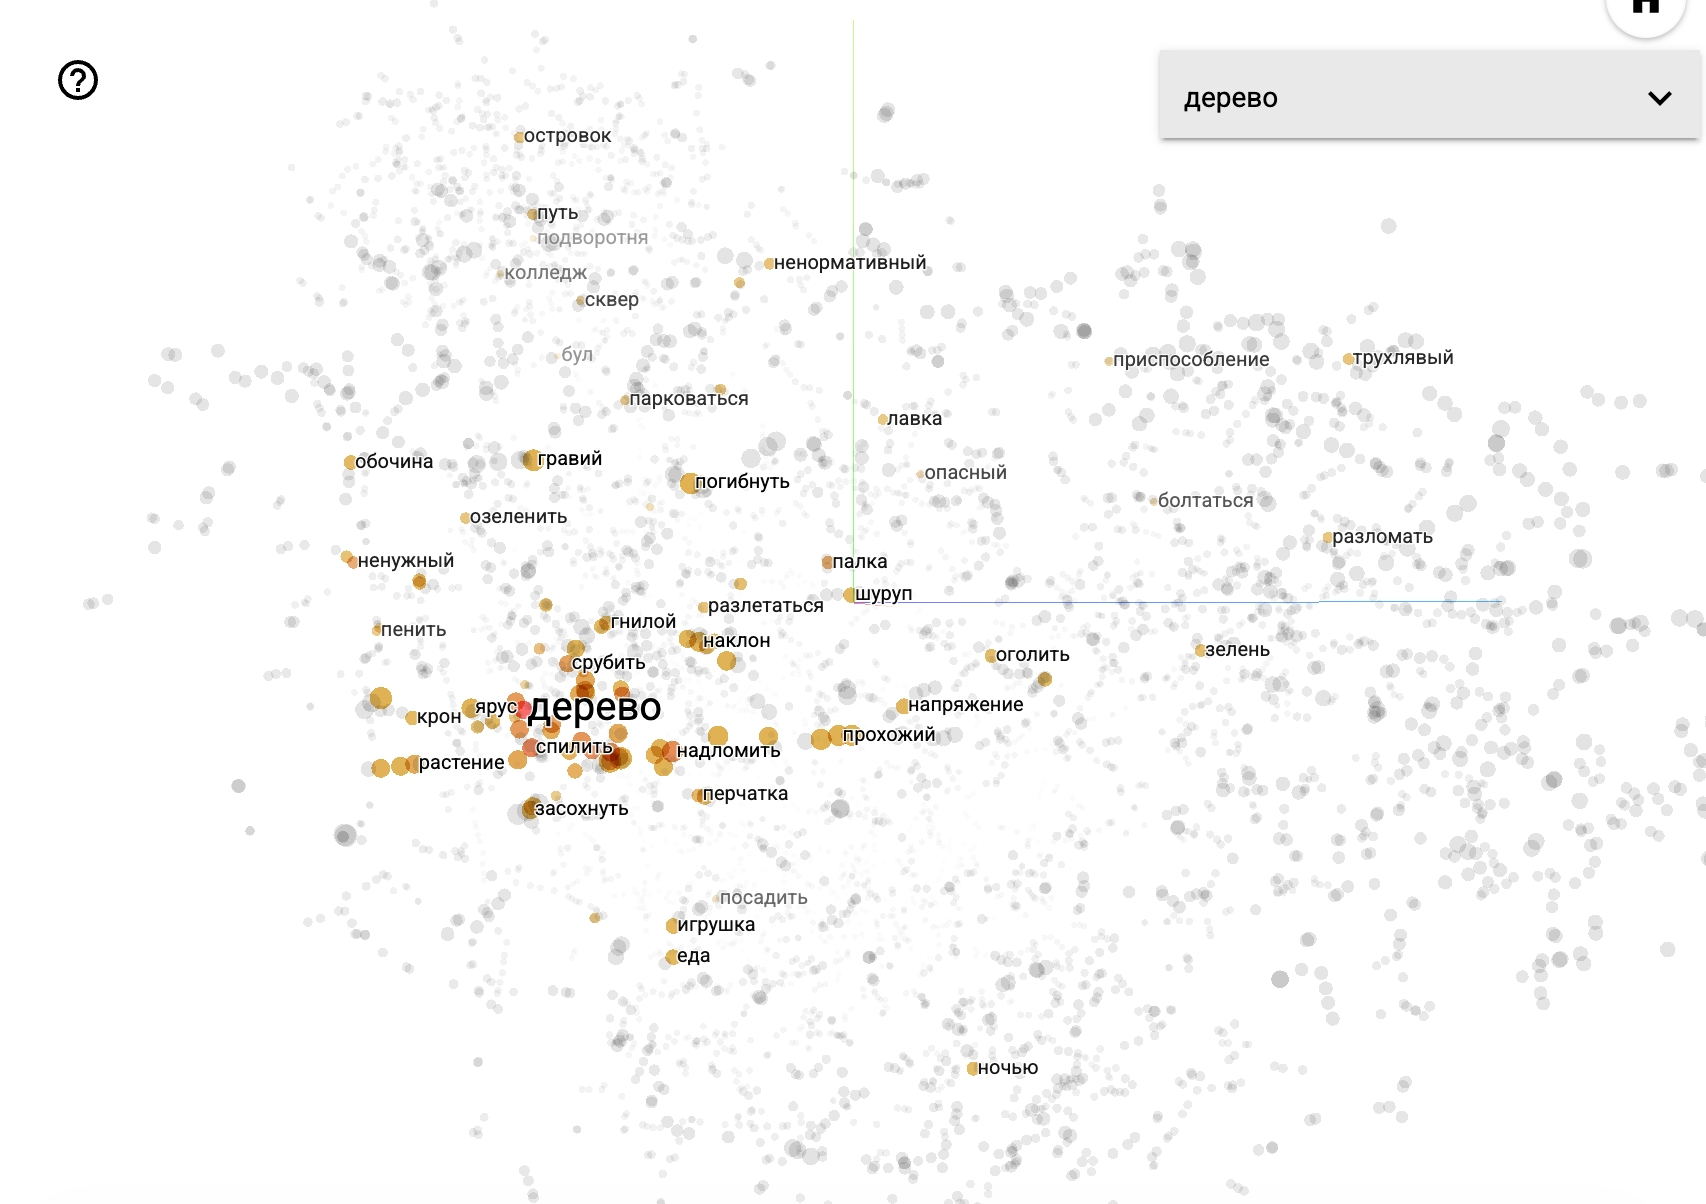

**CBoW** (ближайшие соседи слова «дерево»):
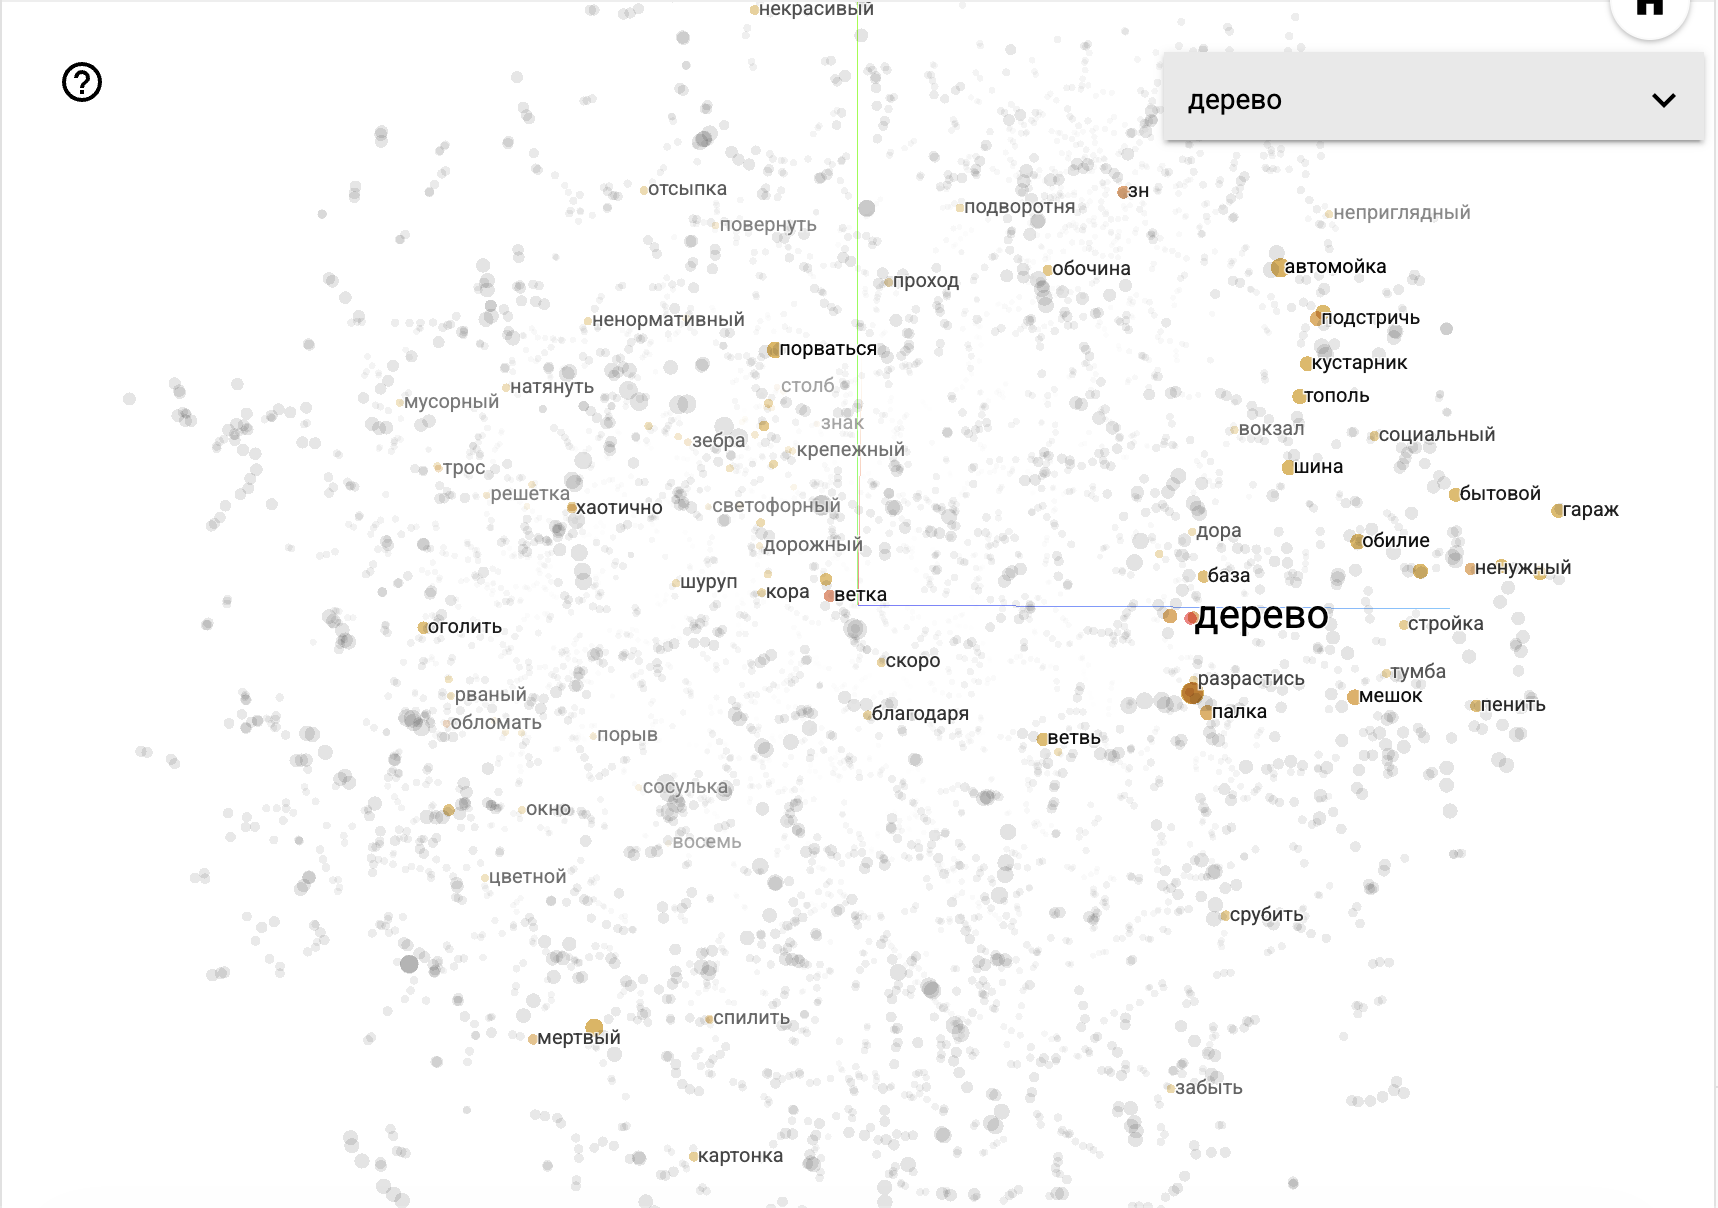

**Матрица совпадений:**
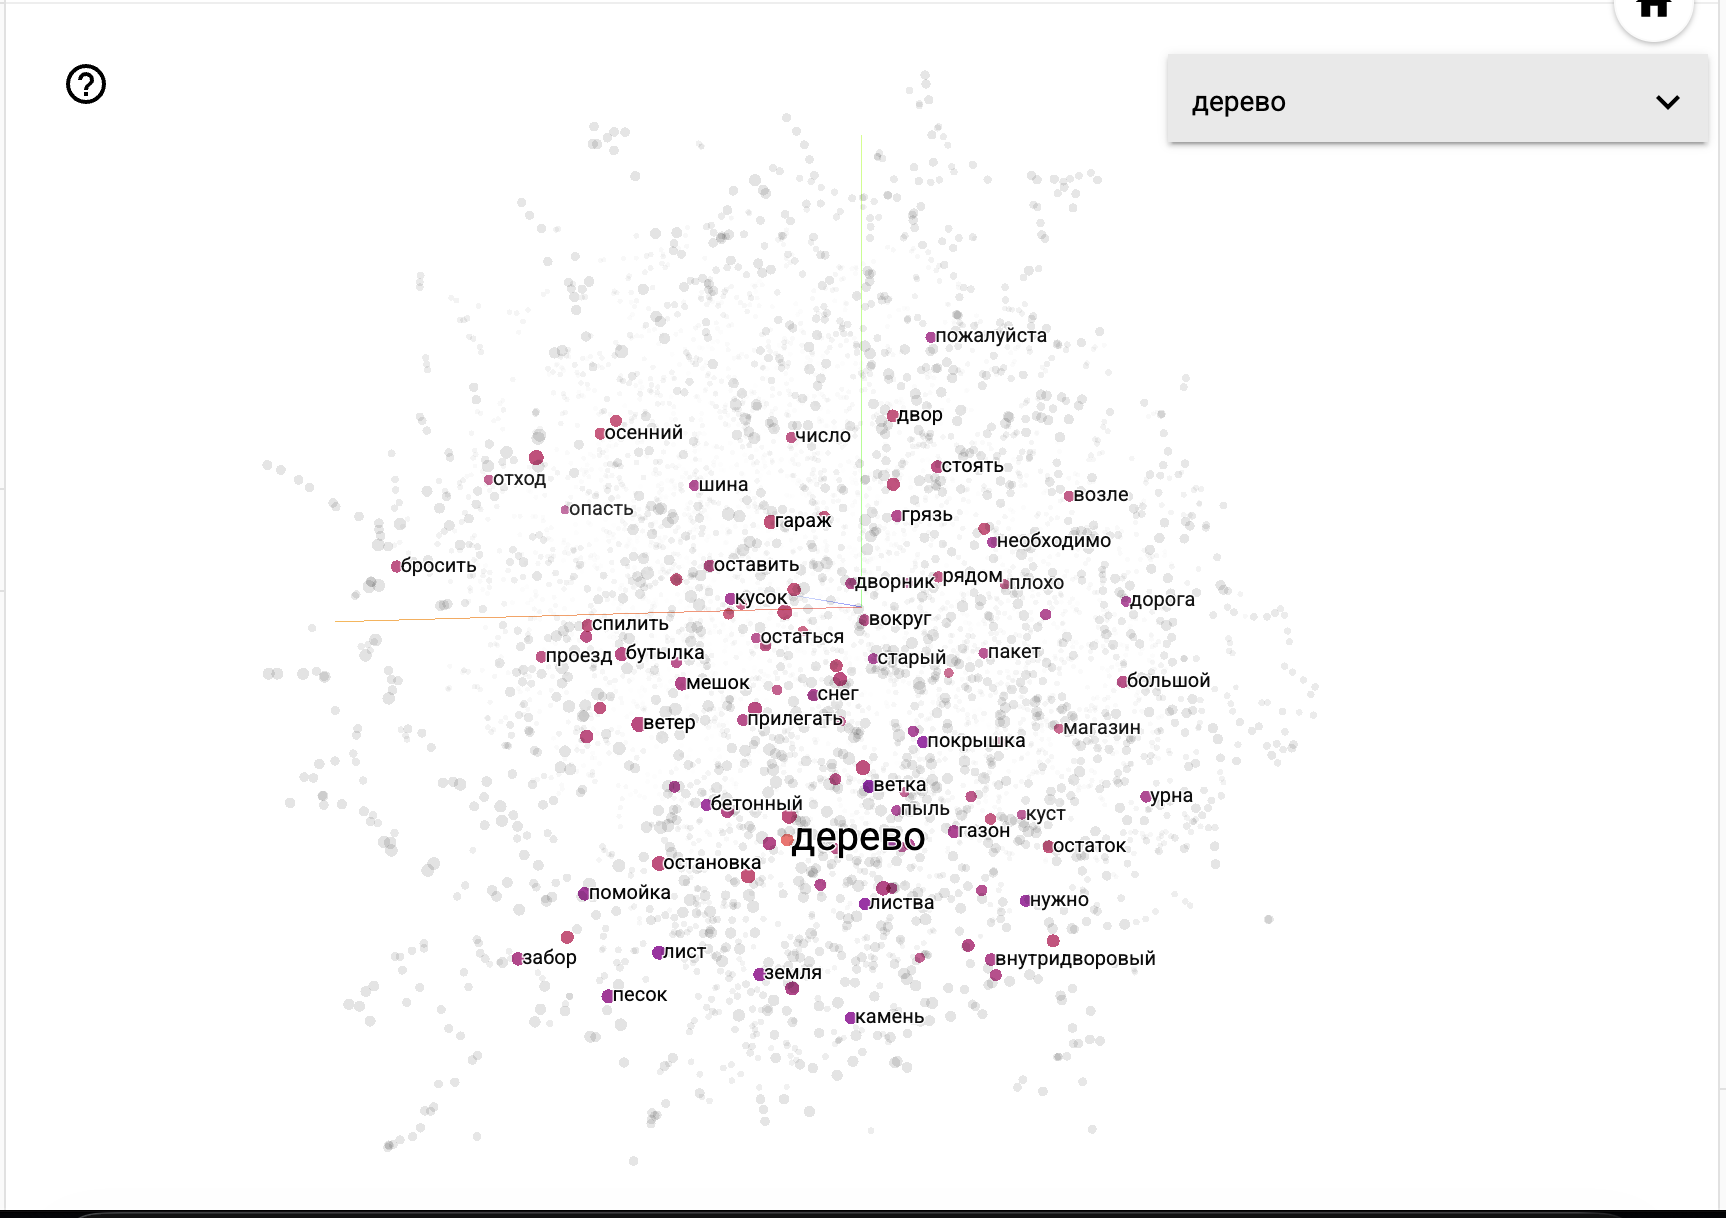

**Векторы текстов (SkipGram), цвет — категория обращения:**
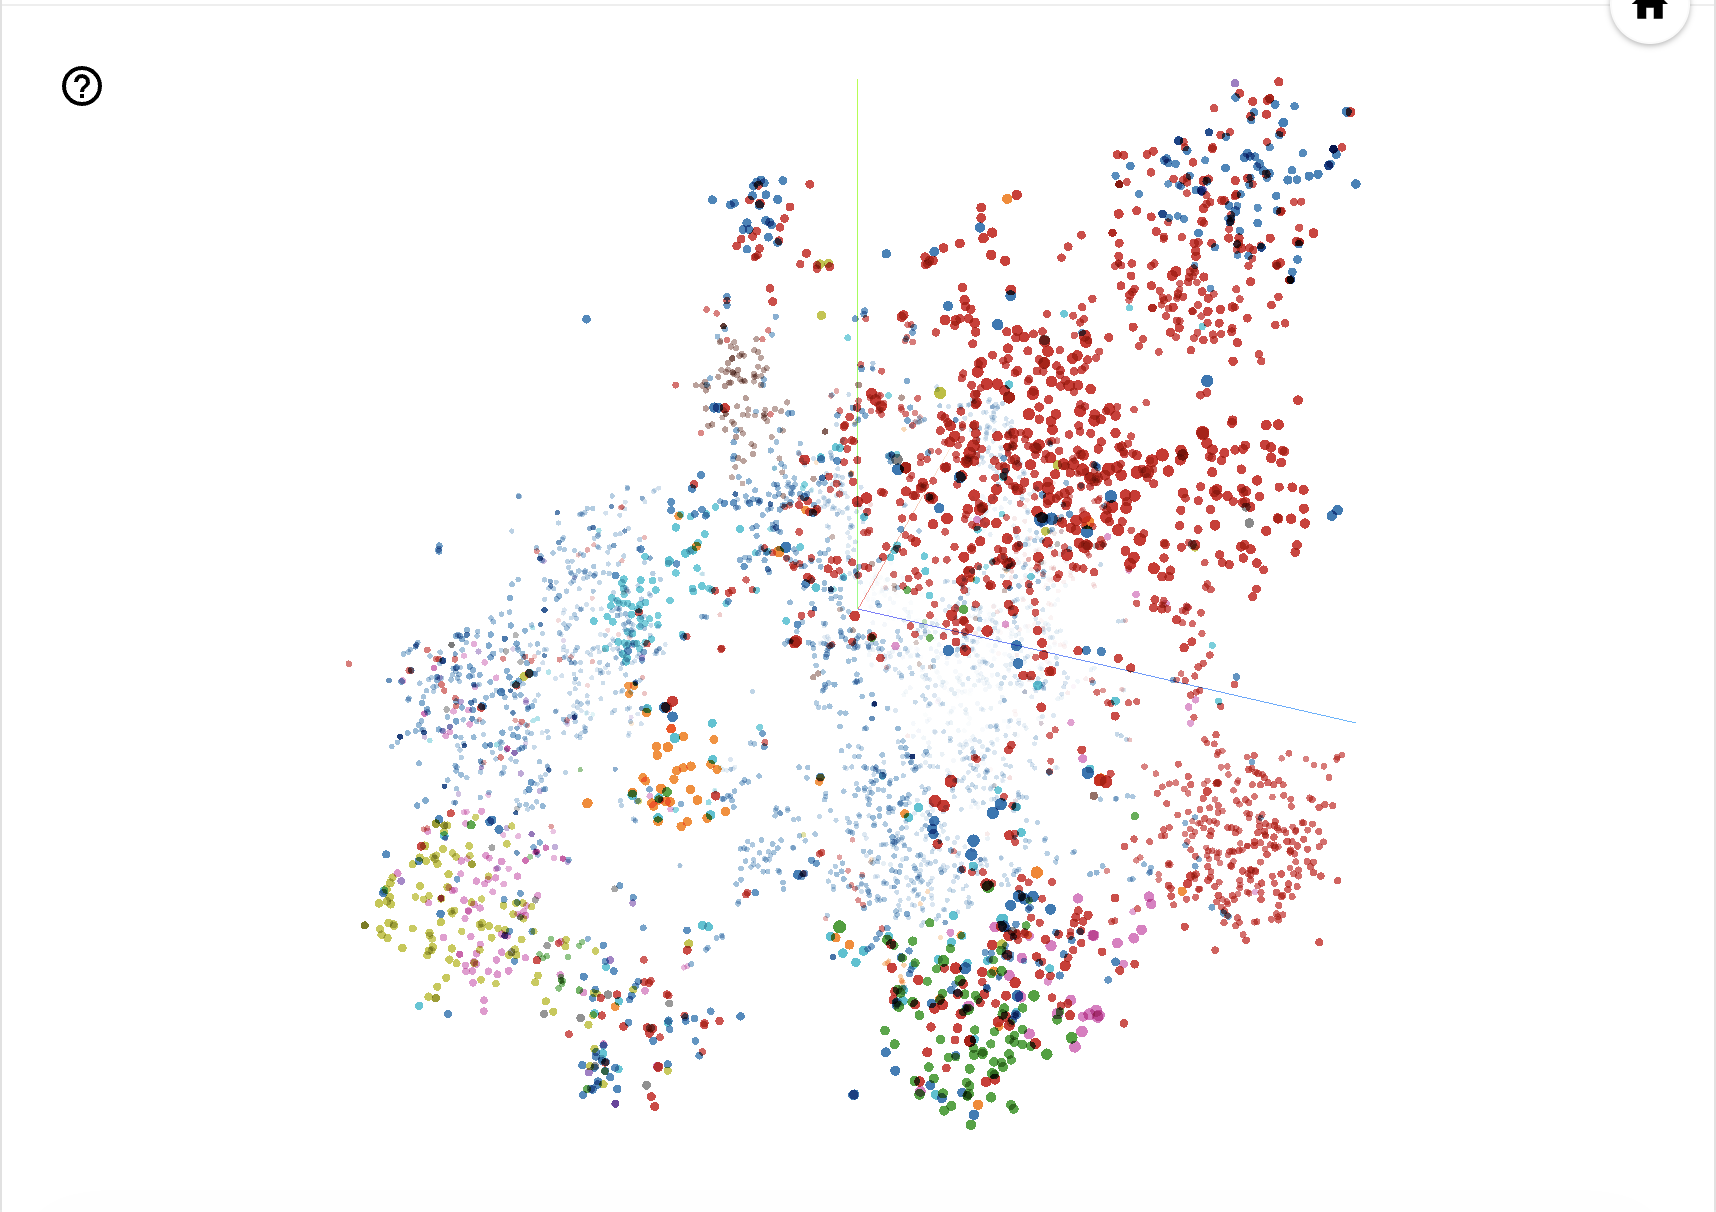